# Injection-recovery: what can the pipeline find, and where should the thresholds be?

Every threshold in steps 3–5 (detrending window, SDE ≥ 9, SNR ≥ 7, each vetting cut) trades
**completeness** (the fraction of real planets we keep) against **purity** (the fraction of what
we keep that is real). Eight known planets in one sector are far too few to measure either. The
standard solution (plan §6, "mandatory before believing anything") is **injection-recovery**:

1. take real light curves, with their real noise, systematics and variability;
2. add synthetic transits of known period, size and epoch;
3. run the *unchanged* pipeline on them;
4. count which come back, and why the others were lost.

Because we know the truth for every injected planet, this measures completeness directly, as a
function of anything we like (period, radius, expected signal-to-noise). The real data, where
almost every surviving signal is a false positive (see the review), measures the other side of
the trade-off.

The injections are run by `src/inject.py` (1,000 injections, ~1.5 h on 10 cores). This
notebook explains its design, traces one injection by hand, and then analyses the results.

Sections:

1. Design of the injections
2. One injection, end to end
3. What counts as "recovered"
4. Recovery vs expected SNR: the detection threshold of the pipeline
5. Recovery in period and planet radius
6. Where injected planets are lost: the cost of every vetting test
7. Choosing the SNR and SDE thresholds
8. Applying the result

## 1. Design of the injections

**Which stars.** Random stars of the sector whose own best signal did *not* pass vetting.
Stars with a real candidate are excluded, so "recovered" can never mean "found the real planet
instead". Stars are drawn with replacement: a quiet star and a noisy star are equally likely,
matching the sector.

**Which planets.** Each injection draws its parameters independently:

| parameter | distribution | why |
|---|---|---|
| period P | log-uniform, 0.3–12 d | one sector supports ≥ 2 transits up to ~12 d; log-uniform gives each factor of 2 in period the same weight |
| planet radius Rp | log-uniform, 0.5–6 R⊕ | from far below to far above our sensitivity, so the transition is resolved |
| impact parameter b | uniform, 0–0.9 | b = 0 is a central transit; ≥ 0.9 would be grazing (see the caveat below) |
| epoch | uniform within the first period | |

Each injection has its own random generator seeded by (seed, injection id), so injection #417
is the same no matter how many are run. A run can be extended from 50 to 1,000 and stays
consistent.

**The transit model** is computed with `batman` (Kreidberg 2015). It implements the analytic
light curve of Mandel & Agol (2002): the fraction of a limb-darkened stellar disk covered by an
opaque disk, as a function of their separation. The planet's path follows from P, a/R★
(Kepler's law with the TIC mass and radius), and the inclination i = arccos(b R★ / a).
Limb darkening is quadratic, $I(\mu)/I(1) = 1 - u_1(1-\mu) - u_2(1-\mu)^2$ with μ = cos of the
angle from disk centre, and $u_1, u_2$ = 0.25, 0.35 (typical for a ~3,400 K dwarf in the TESS
band; Claret 2017). The model is integrated over each exposure (200-s QLP cadences smear a
30-minute transit noticeably).

**Where it is injected.** The model *multiplies the raw normalised flux, before detrending*.
Injecting into the already-flattened light curve would skip the step most likely to damage a
transit (the 0.5-d biweight; see `docs/NOTES_decisions.md`: it keeps ~90 % of a 1-h transit's
depth but only ~75 % of a 2.5-h one). The injected light curve then goes through exactly the
production functions:
`detrend.load_raw` → × model → `detrend.flatten_lc` → `search.search_one` → `vet.vet_one`.

**Thresholds are not applied** in `inject.py`. It stores the metrics, so that this notebook can
apply any set of thresholds with `vet.apply_thresholds` afterwards. The injected light curves are
kept (`data/injection/lc/`), so a change to `vet.py` only needs `python -m src.inject --revet`
(minutes), not a new TLS run (hours).

**Two caveats that make the completeness numbers below slightly optimistic.**

- Real transiting planets have b uniform between 0 and 1 + k, so about 10 % of them are
  grazing (b > 0.9). Those are the shallowest, shortest, V-shaped transits, the hardest to find
  and the ones the shape flag fires on. They are not injected here.
- The expected SNR (§3) uses the injected **central** depth, which limb darkening makes ~15 %
  deeper than the average depth across the transit. Curves plotted against SNR_exp are
  therefore shifted ~10–15 % to the right of where an average-depth SNR would put them.

## 2. One injection, end to end

We inject a 2 R⊕ planet with P = 3.3 d into one star and follow it through every step.

In [1]:
import os
import sys
import warnings
from dataclasses import asdict
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.detrend import flatten_lc, load_raw
from src.inject import recovery_flags, transit_model
from src.search import search_one
from src.vet import HARD, THRESH, apply_thresholds, momentum_dumps, vet_one

warnings.filterwarnings("ignore")
ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = ROOT / "data"
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet").set_index("tic_id")
manifest = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}_manifest.parquet").set_index("tic_id")

TIC, P, RP, B = 201602533, 3.3, 2.0, 0.3  # an ordinary QLP star without a candidate
star = targets.loc[TIC]
raw_file = str(ROOT / manifest.loc[TIC, "file_path"])
t, f, e, _ = load_raw(raw_file)
T0 = t.min() + 1.1
model, depth, dur_h = transit_model(t, P, T0, RP, B, star.rad, star.mass, float(np.median(np.diff(t))))
flat, _ = flatten_lc(t, f * model, e)
print(f"TIC {TIC}: R* = {star.rad:.2f}, M* = {star.mass:.2f}; injected depth {depth*1e6:.0f} ppm, duration {dur_h:.2f} h")

TIC 201602533: R* = 0.37, M* = 0.36; injected depth 2828 ppm, duration 1.42 h


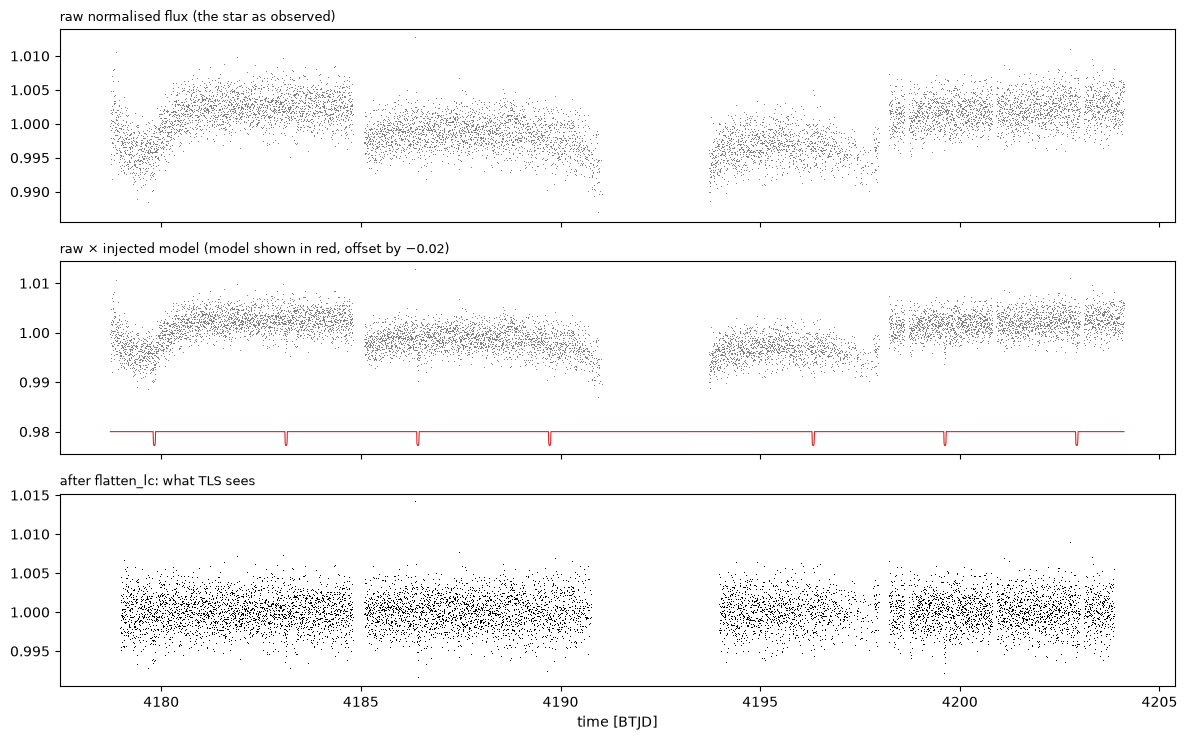

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
axes[0].plot(t, f, ",", color="0.5"); axes[0].set_title("raw normalised flux (the star as observed)", fontsize=9, loc="left")
axes[1].plot(t, f * model, ",", color="0.5"); axes[1].plot(t, model - 0.02, "C3-", lw=0.8)
axes[1].set_title("raw × injected model (model shown in red, offset by −0.02)", fontsize=9, loc="left")
axes[2].plot(flat["time"], flat["flux"], ",k"); axes[2].set_title("after flatten_lc: what TLS sees", fontsize=9, loc="left")
axes[2].set_xlabel("time [BTJD]")
plt.tight_layout()

In [3]:
demo = DATA_DIR / "injection" / "demo_injection.parquet"
flat.to_parquet(demo, index=False)
s = asdict(search_one(TIC, str(demo), star.rad, star.mass))
dumps = momentum_dumps(manifest.reset_index().assign(file_path=lambda d: str(ROOT) + "/" + d["file_path"]))
v = asdict(vet_one(TIC, s, star.to_dict(), str(demo), raw_file, dumps))
row = {**v, "SDE": s["SDE"], "snr_tls": s["snr"], "distinct_transit_count": s["distinct_transit_count"],
       "period": s["period"], "period_max": s["period_max"], "period_unc": s["period_unc"]}
out = apply_thresholds(pd.DataFrame([row])).iloc[0]
print(f"injected: P = {P:.4f} d, T0 = {T0:.4f}, depth {depth*1e6:.0f} ppm, duration {dur_h:.2f} h")
print(f"TLS     : P = {s['period']:.4f} d, T0 = {s['T0']:.4f}, depth {s['depth_ppm']:.0f} ppm, duration {s['duration_h']:.2f} h, "
      f"SDE {s['SDE']:.1f}, SNR {s['snr']:.1f}")
print(f"vetting : passes_all = {out['passes_all']}  failed: {out['failed'] or '-'}  flags: {out['flags'] or '-'}")

2026-10-04 17:16:39,316 INFO [MainProcess] TIC 201602533: SDE 18.2, P 3.2993 d, depth 2505 ppm, 7/8 transits with data, 36 s


injected: P = 3.3000 d, T0 = 4179.8282, depth 2828 ppm, duration 1.42 h
TLS     : P = 3.2993 d, T0 = 4179.8306, depth 2505 ppm, duration 1.14 h, SDE 18.2, SNR 11.8
vetting : passes_all = True  failed: -  flags: -


TLS recovers the injected period and epoch, and the planet passes vetting. TLS's depth is a
bit smaller than the injected central depth (TLS fits an average transit shape, and the
biweight removes a few percent), and its duration is shorter (TLS's duration convention is
close to the flat-bottom time, not first-to-last contact). That is why "recovered" is defined
on period and epoch only.

## 3. What counts as "recovered"

For each injection (`recovery_flags` in `src/inject.py`):

- **found**: TLS's best period is within 1 % of the injected one *and* TLS's epoch lands
  within max(duration, 1 h) of an injected transit. Both are needed. A matching period at the
  wrong phase means TLS found something else.
- **found_alias**: TLS's period is 2×, ½, 3× or ⅓ of the injected one. That signal is our
  planet, but at the wrong period. We count it separately and **not** as recovered: a report
  with the wrong period would be wrong.
- **passes**: found *and* passes all hard vetting tests with the chosen thresholds.

The natural x-axis is the **expected SNR**, the signal-to-noise an ideal matched filter would
reach on that star:

$$\text{SNR}_{\rm exp} = \frac{\delta}{\sigma}\sqrt{N_{\rm in}},$$

with δ the injected depth, σ the star's point-to-point scatter after flattening, and $N_{\rm in}$
the number of in-transit points. It folds period (how many transits), radius (depth), star size
(depth) and noise level into the one number that controls detectability. Two injections with
the same expected SNR should be equally detectable whatever their period and radius.

In [4]:
inj = pd.read_parquet(os.environ.get("INJ_FILE", DATA_DIR / "injection" / f"sector_{SECTOR}_injrec.parquet"))
ok = inj[inj["search_status"] == "ok"].copy()
ok = apply_thresholds(recovery_flags(ok))
ok["passes"] = ok["found"] & ok["passes_all"]
print(f"{len(inj)} injections, {len(ok)} searched without error")
print(f"found: {ok.found.mean():.1%}   found at an alias: {ok.found_alias.mean():.1%}   found and pass vetting: {ok.passes.mean():.1%}")
print(f"(of all injections, {(ok.snr_expected < 5).mean():.0%} have expected SNR < 5: undetectable by construction)")

1000 injections, 1000 searched without error
found: 41.2%   found at an alias: 1.8%   found and pass vetting: 34.2%
(of all injections, 51% have expected SNR < 5: undetectable by construction)


The overall fractions mean little on their own. They mostly reflect how many undetectable
injections the parameter range contains. What matters is the dependence on SNR.

## 4. Recovery vs expected SNR

For each SNR bin, the fraction found, and the fraction found *and* passing vetting, with
binomial error bars $\sqrt{p(1-p)/n}$. A **logistic curve**
$p(x) = p_{\max} / (1 + e^{-k(x - x_{50})})$ fitted to the individual injections (maximum
likelihood, each injection a Bernoulli trial) gives the SNR at which the pipeline finds half
of the planets ($x_{50}$), and its plateau $p_{\max}$.

found by the search       : plateau 94.6%, 50 % at SNR_exp = 7.0, 90 % of plateau at 9.3
found and passes vetting  : plateau 89.2%, 50 % at SNR_exp = 8.7, 90 % of plateau at 10.1


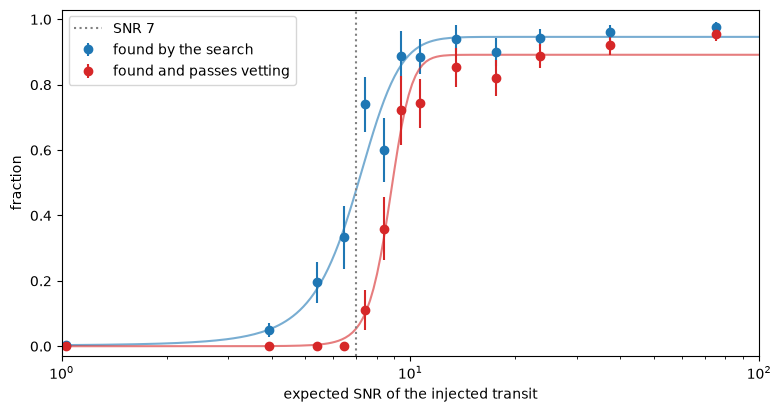

In [5]:
from scipy.optimize import minimize


def logistic(x, pmax, k, x50):
    return pmax / (1 + np.exp(-k * (x - x50)))


def fit_logistic(x, y):
    '''Maximum-likelihood logistic fit to 0/1 outcomes y at positions x.'''
    def nll(p):
        pm, k, x50 = p
        if not (0 < pm <= 1 and k > 0):
            return 1e9
        q = np.clip(logistic(x, pm, k, x50), 1e-9, 1 - 1e-9)
        return -np.sum(y * np.log(q) + (1 - y) * np.log(1 - q))
    return minimize(nll, [0.95, 1.0, 8.0], method="Nelder-Mead").x


bins = np.array([0, 3, 5, 6, 7, 8, 9, 10, 12, 15, 20, 30, 50, 1000])
x = ok["snr_expected"].to_numpy()
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c, lab in [("found", "C0", "found by the search"), ("passes", "C3", "found and passes vetting")]:
    y = ok[col].to_numpy().astype(float)
    idx = np.digitize(x, bins) - 1
    mids, frac, err = [], [], []
    for i in range(len(bins) - 1):
        m = idx == i
        if m.sum() >= 5:
            p = y[m].mean()
            mids.append(np.median(x[m])); frac.append(p); err.append(np.sqrt(p * (1 - p) / m.sum()))
    ax.errorbar(mids, frac, err, fmt="o", color=c, label=lab)
    pm, k, x50 = fit_logistic(x, y)
    xx = np.logspace(0, 2, 200)
    ax.plot(xx, logistic(xx, pm, k, x50), "-", color=c, alpha=0.6)
    x90 = x50 + np.log(0.9 / (1 - 0.9)) / k if pm > 0.9 else np.nan
    print(f"{lab:26s}: plateau {pm:.1%}, 50 % at SNR_exp = {x50:.1f}, 90 % of plateau at {x50 + np.log(9) / k:.1f}")
ax.set_xscale("log"); ax.set_xlim(1, 100); ax.set_ylim(-0.03, 1.03)
ax.axvline(7, color="0.5", ls=":", label="SNR 7")
ax.set_xlabel("expected SNR of the injected transit"); ax.set_ylabel("fraction"); ax.legend()

How to read this:

- The **search curve** rises from ~0 to its plateau over a narrow SNR range. Its midpoint is
  the pipeline's real detection threshold. It is not exactly 7, because TLS's SNR and our
  ideal SNR differ, and because red noise and systematics make real light curves worse than the
  white-noise ideal.
- The **gap between the curves** is the cost of vetting: real planets found by TLS and then
  rejected. Near the threshold it is mostly the SNR and SDE cuts themselves. On the plateau it
  is the other tests (§6).
- The **plateau below 100 %** means that even very strong signals are sometimes lost. §6 shows
  why.

## 5. Recovery in period and planet radius

The same results on the plane astronomers think in. Each cell shows the fraction of injections
that are found and pass vetting, with the number of injections in the cell. The plan's goal
(§6) was "> 80 % recovery at 3 mmag / P < 10 d". A 3-mmag (3,000 ppm) transit on a 0.3 R☉ star
is a ~1.8 R⊕ planet.

plan goal check, depth >= 3,000 ppm and P < 10 d: 73% of 362 injections found and pass vetting (80% found by the search)


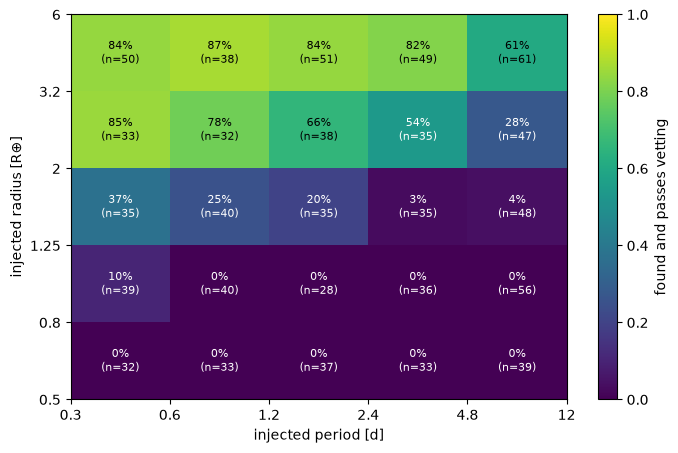

In [6]:
p_edges = np.array([0.3, 0.6, 1.2, 2.4, 4.8, 12.0])
r_edges = np.array([0.5, 0.8, 1.25, 2.0, 3.2, 6.0])
H = np.full((len(r_edges) - 1, len(p_edges) - 1), np.nan)
N = np.zeros_like(H)
for i in range(len(r_edges) - 1):
    for j in range(len(p_edges) - 1):
        m = ok.rp_inj_earth.between(r_edges[i], r_edges[i + 1]) & ok.P_inj.between(p_edges[j], p_edges[j + 1])
        N[i, j] = m.sum()
        if m.sum():
            H[i, j] = ok.loc[m, "passes"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(H, origin="lower", cmap="viridis", vmin=0, vmax=1, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if N[i, j]:
            ax.text(j, i, f"{H[i, j]:.0%}\n(n={int(N[i, j])})", ha="center", va="center", fontsize=8,
                    color="w" if H[i, j] < 0.6 else "k")
ax.set_xticks(np.arange(len(p_edges)) - 0.5, [f"{p:g}" for p in p_edges])
ax.set_yticks(np.arange(len(r_edges)) - 0.5, [f"{r:g}" for r in r_edges])
ax.set_xlabel("injected period [d]"); ax.set_ylabel("injected radius [R⊕]")
plt.colorbar(im, label="found and passes vetting")

goal = ok[(ok.depth_inj_ppm >= 3000) & (ok.P_inj < 10)]
print(f"plan goal check, depth >= 3,000 ppm and P < 10 d: {goal.passes.mean():.0%} of {len(goal)} injections "
      f"found and pass vetting ({goal.found.mean():.0%} found by the search)")

Completeness falls towards **small radii** (shallower transits) and **long periods** (fewer
transits, and longer durations that the biweight partly removes). For a typical M dwarf,
planets ≳ 2 R⊕ inside ~5 days are found most of the time, and Earth-size planets only on the
quietest, smallest stars at short periods. Any statement about planet *occurrence* from this
search would have to divide by this map.

## 6. Where injected planets are lost

Two stages lose planets: the search (TLS returns a different period) and vetting (a test
rejects a correctly found planet). First the search.

In [7]:
strong = ok[ok.snr_expected >= 15]
missed = strong[~strong.found]
print(f"expected SNR >= 15: {len(strong)} injections, {len(missed)} not found "
      f"({missed.found_alias.sum()} of them at an alias of the injected period)")
missed[["inj_id", "tic_id", "P_inj", "rp_inj_earth", "depth_inj_ppm", "dur_inj_h", "snr_expected", "period", "SDE",
        "found_alias"]].round(3).head(12)

expected SNR >= 15: 289 injections, 14 not found (4 of them at an alias of the injected period)


,inj_id,tic_id,P_inj,rp_inj_earth,depth_inj_ppm,dur_inj_h,snr_expected,period,SDE,found_alias
143,429,91640026,3.280,3.445,13120.382,1.149,25.887,6.561,23.513,True
283,146,304701559,10.690,3.681,5331.227,2.689,16.007,5.344,11.344,True
344,944,61965286,0.303,5.780,12276.822,0.845,94.411,0.606,24.847,True
639,805,22494311,0.303,2.490,1799.441,0.910,28.788,0.606,17.153,True
642,644,80429031,7.131,5.554,15515.980,1.365,16.752,1.187,10.628,False
667,7,355766445,5.274,3.643,3476.821,2.191,30.054,6.726,8.947,False
824,597,303696309,1.091,3.258,4417.322,1.042,15.020,0.492,5.398,False
875,771,38820496,0.316,3.520,11372.271,0.376,21.155,0.656,20.593,False
902,785,470289424,0.928,3.850,6960.949,1.134,21.424,1.070,8.886,False
910,50,122504261,6.687,3.156,20957.454,1.344,19.470,0.737,8.758,False


The strong-but-missed injections fall into a few groups. Look at the TLS period column:

- **aliases** (2P, P/2): TLS lines up only every other transit, typically when transits fall
  in the gaps;
- **another, stronger signal on the same star**: variability or systematics produce a
  higher SDE than the injected planet, and TLS reports only the best signal. This is what the
  second-pass search exists for;
- **very long durations at long periods**, where flattening has removed part of the depth.

Now vetting. For every injection that the search **did** find, which hard tests reject it?
That is each test's **false-rejection rate**, its cost in real planets. Next to it is the
fraction of the real sector's SDE ≥ 9 signals that the same test rejects, i.e. what it buys.

In [8]:
vetted = pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}_vetted.parquet")
real = vetted[vetted.pass_sde & vetted.pass_n_transits]
found = ok[ok.found]
cost = pd.DataFrame({
    "rejects injected planets (found)": {k: (~found[f"pass_{k}"]).mean() for k in HARD},
    "of which ONLY this test": {k: ((~found[f"pass_{k}"]) & (found["failed"] == k)).mean() for k in HARD},
    "rejects real SDE>=9 signals": {k: (~real[f"pass_{k}"]).mean() for k in HARD},
})
cost.style.format("{:.1%}")

,rejects injected planets (found),of which ONLY this test,rejects real SDE>=9 signals
sde,9.5%,0.7%,0.0%
snr,12.4%,4.4%,11.1%
n_transits,0.0%,0.0%,0.0%
grid_edge,0.0%,0.0%,1.3%
single_event,0.2%,0.0%,2.3%
momentum_dump,0.2%,0.0%,6.2%
data_edges,1.9%,1.5%,10.1%
transit_noise,0.2%,0.2%,2.9%
odd_even,1.0%,0.7%,8.2%
secondary,0.0%,0.0%,31.7%


Reading the table row by row:

- A test that rejects **many real signals and few injected planets** is doing its job
  (`secondary`, `variability`, `odd_even`).
- A test whose column "ONLY this test" is non-zero is the *sole* reason some real planets are
  lost. Those are the ones worth tuning.
- The SNR and SDE cuts dominate the planet losses, as expected: they are the detection
  threshold itself. §7 tunes them.

### 6.1 What this table changed (vetting v3, 2026-10-04)

Two rows of this table used to be non-zero in "ONLY this test" for strong, correctly found
planets:

- `duration` rejected 8 found planets with ratios 0.09–0.32. TLS's duration estimate is coarse
  for short transits, and most had small impact parameters, so the geometry was not the cause.
  The lower bound was removed (notebook 5, §8.1). At the same time the upper bound went from 3 to
  1.5: 99 % of found injections are ≤ 1.01, and 9 real signals at 1.5–2.3 were all blends or EBs.
- `secondary` rejected 5 bright planets (expected SNR 20–355) for 5–6.7σ dips at random phases.
  The 5σ threshold now applies near phase 0.5 only, with 7σ elsewhere (notebook 5, §7).

Effect, at the same SNR/SDE thresholds: 342 instead of 339 found injections pass, the
completeness at SNR_exp ≥ 7 goes from 79.2 % to 79.9 %, and 31 instead of 40 real signals pass.
Most of the recovered planets were also below the SNR/SDE cuts, which is why the gain is small.

## 7. Choosing the SNR and SDE thresholds

Lowering a threshold recovers more injected planets (completeness ↑) and lets more real
false positives through (purity ↓). We quantify both for a grid of thresholds:

- **completeness**: the fraction of injections with expected SNR ≥ 7 that are found and pass
  vetting. Below that the search rarely finds anything, so including them only dilutes the
  number;
- **cost**: the number of real sector-104 signals that pass all hard tests. The review
  graded almost all of them as false positives, so this is essentially the human workload of
  false alarms.

Two SNR definitions are compared. **TLS's `snr_tls`**, used so far, assumes white noise
everywhere. **Our `snr`** from vetting uses the local, red-noise-corrected per-transit errors
(notebook 5, §5.1). It is lower for signals that live in noisy stretches (TIC 49143293: 8.5
vs 5.4).

completeness               real signals passing            
sde_min                    8.0    9.0    10.0                 8.0   9.0   10.0
snr column snr_min                                                            
snr        5.0            0.846  0.841  0.829                154.0  75.0  44.0
           5.5            0.841  0.836  0.825                 78.0  49.0  38.0
           6.0            0.825  0.822  0.811                 49.0  39.0  35.0
           6.5            0.790  0.790  0.785                 37.0  33.0  31.0
           7.0            0.771  0.771  0.766                 32.0  29.0  28.0
           7.5            0.759  0.759  0.757                 26.0  24.0  24.0
           8.0            0.724  0.724  0.722                 23.0  22.0  22.0
snr_tls    5.0            0.843  0.839  0.827                179.0  81.0  43.0
           5.5            0.843  0.839  0.827                103.0  57.0  40.0
           6.0            0.820  0.820  0.808                 57.0  43.0  36.0
           6.5            0.804  0.804  0.799                 44.0  37.0  31.0
           7.0            0.771  0.771  0.769                 37.0  32.0  30.0
           7.5            0.762  0.762  0.759                 32.0  29.0  28.0
           8.0            0.727  0.727  0.727                 28.0  25.0  24.0

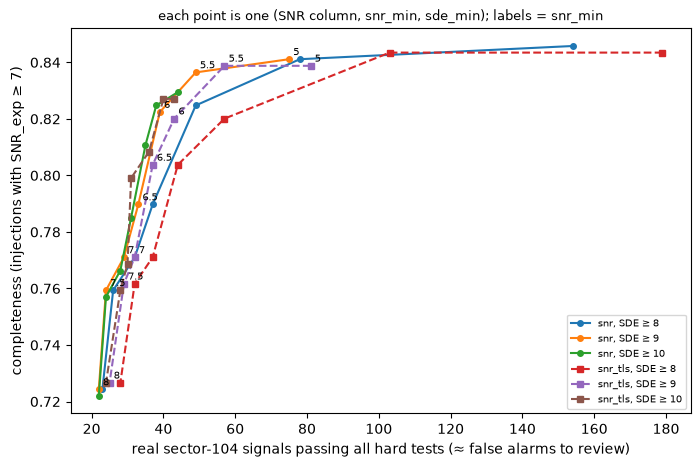

In [9]:
def n_real_passing(thresh):
    return int(apply_thresholds(vetted.drop(columns=[c for c in vetted.columns if c.startswith(("pass_", "flag_"))]
                                            + ["passes_all", "n_flags", "failed", "flags"]), thresh)["passes_all"].sum())


def completeness(thresh, min_snr_exp=7):
    sub = ok[ok.snr_expected >= min_snr_exp]
    v = apply_thresholds(sub.drop(columns=[c for c in sub.columns if c.startswith(("pass_", "flag_"))]
                                  + ["passes_all", "n_flags", "failed", "flags"]), thresh)
    return float((v["found"] & v["passes_all"]).mean())


rows = []
for snr_col in ("snr_tls", "snr"):
    for snr_min in (5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0):
        for sde_min in (8.0, 9.0, 10.0):
            th = {**THRESH, "snr_min": snr_min, "sde_min": sde_min, "snr_column": snr_col}
            rows.append({"snr column": snr_col, "snr_min": snr_min, "sde_min": sde_min,
                         "completeness": completeness(th), "real signals passing": n_real_passing(th)})
grid = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 5))
for (col, sde), g in grid.groupby(["snr column", "sde_min"]):
    ax.plot(g["real signals passing"], g["completeness"], "o-" if col == "snr" else "s--", ms=4,
            label=f"{col}, SDE ≥ {sde:g}")
    for _, r in g.iterrows():
        if sde == 9:
            ax.annotate(f"{r.snr_min:g}", (r["real signals passing"], r.completeness), fontsize=7, xytext=(3, 3),
                        textcoords="offset points")
ax.set_xlabel("real sector-104 signals passing all hard tests (≈ false alarms to review)")
ax.set_ylabel("completeness (injections with SNR_exp ≥ 7)")
ax.set_title("each point is one (SNR column, snr_min, sde_min); labels = snr_min", fontsize=9)
ax.legend(fontsize=7)
grid.pivot_table(index=["snr column", "snr_min"], columns="sde_min", values=["completeness", "real signals passing"]).round(3)

Every curve bends: at first, lowering the threshold buys completeness cheaply, then each extra
percent costs many more false alarms. The good choice is near the **knee**.

**Decision rule.** Prefer a setting that **dominates** the current one (SNR_TLS ≥ 7, SDE ≥ 9),
meaning it is at least as complete *and* lets through no more real false alarms. Among those,
take the most complete. Any dominating setting is better on both axes, so this choice needs no
judgement about how many false alarms one planet is worth. The next cell applies the rule to
the grid, so the text cannot drift from the numbers.

**How much to trust the winner.** The grid has 42 settings, scored on the same 1,000
injections and the same sector, so the best one is chosen partly on noise. Differences of a
few percent in completeness (≈ 600 injections with SNR_exp ≥ 7, binomial error ~1.7 %) and of
a few real signals are not significant. Treat the choice as "about this region of the grid",
and re-check it on the next sector.

In [10]:
cur = grid[(grid["snr column"] == "snr_tls") & (grid.snr_min == 7.0) & (grid.sde_min == 9.0)].iloc[0]
dominating = grid[(grid.completeness >= cur.completeness - 1e-9) & (grid["real signals passing"] <= cur["real signals passing"])]
best = dominating.sort_values(["completeness", "real signals passing"], ascending=[False, True]).iloc[0]
print(f"current : snr_tls >= 7, SDE >= 9 -> completeness {cur.completeness:.1%}, {int(cur['real signals passing'])} real signals pass")
print(f"settings that dominate it: {len(dominating) - 1}")
print(dominating.sort_values("completeness", ascending=False).round(3).to_string(index=False))
print(f"\nchosen  : {best['snr column']} >= {best.snr_min:g}, SDE >= {best.sde_min:g} -> completeness "
      f"{best.completeness:.1%}, {int(best['real signals passing'])} real signals pass")
known_sde = vetted.merge(pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}_known.parquet")[["tic_id", "known_class"]],
                         on="tic_id")
kp = known_sde[known_sde.known_class == "known_planet"][["tic_id", "SDE", "snr_tls", "snr"]]
print("\nknown planets under the chosen thresholds:")
print(kp.assign(passes_sde=kp.SDE >= best.sde_min, passes_snr=kp[best["snr column"]] >= best.snr_min).round(2).to_string(index=False))

current : snr_tls >= 7, SDE >= 9 -> completeness 77.1%, 32 real signals pass
settings that dominate it: 4
snr column  snr_min  sde_min  completeness  real signals passing
   snr_tls      6.5     10.0         0.799                    31
       snr      6.5     10.0         0.785                    31
   snr_tls      7.0      9.0         0.771                    32
       snr      7.0      8.0         0.771                    32
       snr      7.0      9.0         0.771                    29

chosen  : snr_tls >= 6.5, SDE >= 10 -> completeness 79.9%, 31 real signals pass

known planets under the chosen thresholds:
   tic_id   SDE  snr_tls   snr  passes_sde  passes_snr
410153553 32.31    32.39 30.61        True        True
234994474 19.37    17.35 17.45        True        True
370133522 26.52    16.52 16.78        True        True
262530407 19.44    24.04 15.46        True        True
351601843 18.41    11.71 12.08        True        True
161032923 17.54     8.80  8.96        True       

## 8. Applying the result

`vet.py` reads the SNR column from `THRESH["snr_column"]`, and every threshold can be changed
without recomputing anything:

```bash
uv run python -m src.vet --rethreshold --snr-min <value> --sde-min <value>   # seconds
uv run python -m src.known
uv run python -m src.report
```

The chosen thresholds, the reasoning, and the before/after numbers are recorded in
`docs/NOTES_decisions.md`.

**What injection-recovery does *not* measure.** The injections are planets on the target
star. They say nothing about how many *false positives* survive, which is why the real-data
count (§7) is needed. They also do not include blends (a planet on a neighbour), which are a
false-positive source for the known-object step, not a completeness issue.